In [3]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import numpy as np
import tensorflow as tf
from keras import layers

def evaluate_model(y_true, y_pred, scores, time, threshold=0.2, model_name="Model"):
    """
    Evaluates a model and returns metrics formatted for copy-pasting.
    
    Parameters:
        y_true (np.array): Ground truth labels (0=normal, 1=anomaly).
        scores (np.array): Anomaly scores (lower = more anomalous).
        threshold (float): Threshold for anomaly decision.
        model_name (str): Name of the model.
        
    Returns:
        dict: Dictionary of metrics (can print or format for LaTeX).
    """

    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auroc = roc_auc_score(y_true, scores)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred, digits=2)

    result = {
        "Model": model_name,
        "Precision": f"{precision:.3f}",
        "Accuracy": f"{accuracy:.3f}",
        "Recall": f"{recall:.3f}",
        "F1-Score": f"{f1:.3f}",
        "Matrix": f"TP={cm[1,1]}, FP={cm[0,1]}, FN={cm[1,0]}, TN={cm[0,0]}",
        "AUROC": f"{auroc:.3f}",
        "Data Loading + Inference Time (s)": f"{time:.4f}s",
        "Clf Report": clf_report.strip()
    }

    return result


2025-07-21 18:03:37.208581: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-07-21 18:03:37.230882: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
@tf.keras.utils.register_keras_serializable()
class AnomalyDetector(tf.keras.Model):
    def __init__(self, **kwargs):
        super(AnomalyDetector, self).__init__(**kwargs)
        self.encoder = tf.keras.Sequential([
          # layers.Dense(16, activation="relu"),
          # # Model was overfitting so add dropout layers
          # layers.Dropout(0.2),
          # layers.Dense(8, activation="relu"),
          # layers.Dropout(0.2),
          # layers.Dense(4, activation="relu")

            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(12, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU()
        ])
    
        self.decoder = tf.keras.Sequential([

            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(24)
            
          # layers.Dense(8, activation="relu"),
          # layers.Dropout(0.2),
          # layers.Dense(16, activation="relu"),
          # layers.Dropout(0.1),
          # layers.Dense(24)
        ])
      
    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

    def get_config(self):
        # Return config dictionary; empty because no constructor args
        base_config = super(AnomalyDetector, self).get_config()
        return base_config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

NameError: name 'tf' is not defined

In [60]:
import pandas as pd

qae_model = tf.keras.models.load_model(
    "Models/12f_cae_model.keras",
    custom_objects={"AnomalyDetector": AnomalyDetector}
)

In [61]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

In [62]:
transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

In [63]:
transformed_validation_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_validation_data.csv')

# 1. Extract labels (column 6)
validation_labels = transformed_validation_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
validation_data = transformed_validation_data.drop(
    columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]]
)

# 3. Convert to float32 tensor
validation_data = tf.convert_to_tensor(validation_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
validation_labels = tf.convert_to_tensor(validation_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)

In [77]:
import time
from sklearn.preprocessing import MinMaxScaler

start_time = time.time()

reduced_testing_data = qae_model.encoder(testing_data)

# --- SCALE TO [0, 2π] ---
scaler = MinMaxScaler(feature_range=(0, 2 * np.pi))
scaled_testing_data = scaler.fit_transform(reduced_testing_data)

end_time = time.time()
loading_time = end_time - start_time
print(f"Data Loading Time {loading_time:.3f}s")

# Loading for Threshold
reduced_normal_training_data = qae_model.encoder(normal_training_data)
scaler = MinMaxScaler(feature_range=(0, 2 * np.pi))
scaled_normal_training_data = scaler.fit_transform(reduced_normal_training_data)

# Loading for Validation
reduced_normal_validation_data = qae_model.encoder(normal_validation_data)
scaler = MinMaxScaler(feature_range=(0, 2 * np.pi))
scaled_validation_data = scaler.fit_transform(reduced_normal_validation_data)

Data Loading Time 0.045s


In [65]:
from qiskit.qpy import load

model_name = "Models/12f_qae_dense_ra"

with open(f"{model_name}/qc.qpy", "rb") as f:
    qc = load(f)[0]  # returns a list of circuits
input_names = np.load(f"{model_name}/input_param_names.npy", allow_pickle=True)
weight_names = np.load(f"{model_name}/weight_param_names.npy", allow_pickle=True)

input_params = [p for p in qc.parameters if p.name in input_names]
weight_params = [p for p in qc.parameters if p.name in weight_names]


trained_params = np.load(f"{model_name}/trained_parameters.npy")


In [66]:
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit.primitives import StatevectorSampler as Sampler

sampler = Sampler()

def identity_interpret(x):
    return x


qnn = SamplerQNN(
    circuit=qc,
    input_params=input_params,
    weight_params=weight_params,
    interpret=identity_interpret,
    output_shape=2,
    sampler=sampler,
)

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


In [67]:
from tqdm import tqdm

def compute_anomaly_scores(qnn, input_data, trained_params, batch_size):
    scores = []
    n_samples = len(input_data)
    
    start = time.time()
    
    for i in tqdm(range(0, n_samples, batch_size), desc="Running inference"):
        batch = input_data[i:i + batch_size]
        probs = qnn.forward(batch, trained_params)
        batch_scores = probs[:, 1]
        scores.extend(batch_scores)
    
    elapsed = time.time() - start
    print(f"\nAll batches processed in {elapsed:.2f} seconds.")
    
    return np.array(scores), elapsed

In [69]:
from sklearn.metrics import roc_curve

n_total = len(scaled_normal_training_data)
n_subset = n_total // 4
subset_indices = np.random.choice(n_total, n_subset, replace=False)
subset_training_data = tf.gather(scaled_normal_training_data, subset_indices)
subset_training_labels = tf.gather(training_labels, subset_indices)

train_scores, inference_time = compute_anomaly_scores(qnn, subset_training_data, trained_params, batch_size=256)

normal_scores = train_scores[subset_training_labels.numpy() == 0]

fpr, tpr, thresholds = roc_curve(np.array(subset_training_labels).astype(int), train_scores)
optimal_idx = np.argmax(tpr - fpr)
threshold = thresholds[optimal_idx]

print(f"Threshold: {threshold}")

Running inference: 100%|██████████████████████| 745/745 [19:01<00:00,  1.53s/it]


All batches processed in 1141.92 seconds.
Threshold: 0.3076171875


Model: 12F Dense + RealAmplitude QAE
Precision: 0.923
Accuracy: 0.895
Recall: 0.965
F1-Score: 0.944
Matrix: TP=165418, FP=13753, FN=6041, TN=3755
AUROC: 0.687
Data Loading + Inference Time (s): 1198.9483s
Clf Report: precision    recall  f1-score   support

       False       0.38      0.21      0.28     17508
        True       0.92      0.96      0.94    171459

    accuracy                           0.90    188967
   macro avg       0.65      0.59      0.61    188967
weighted avg       0.87      0.90      0.88    188967


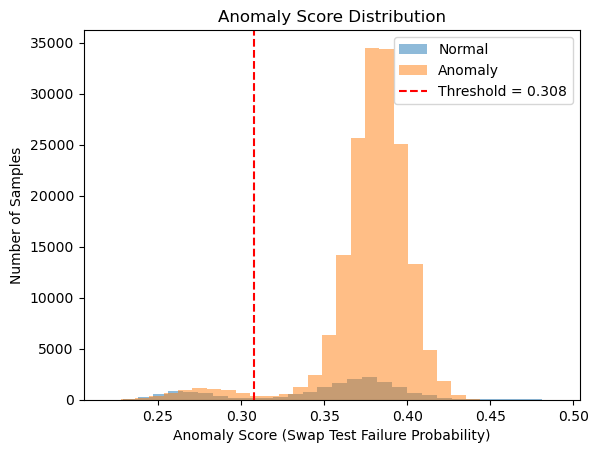

In [73]:
# Get predictions
import matplotlib.pyplot as plt

scores, inference_time = compute_anomaly_scores(qnn, scaled_testing_data, trained_params, batch_size=256)

y_pred = (scores > threshold).astype(int)
y_true = np.array(testing_labels).astype(int)

# Your true labels for this test data
y_true = testing_labels  # shape should be (n_samples,), values = 0 or 1

time = inference_time + loading_time

metrics = evaluate_model(
    y_true=y_true,
    y_pred=y_pred,
    scores=scores,
    time=time,
    threshold=threshold,  # same threshold used in predict
    model_name="12F Dense + RealAmplitude QAE"
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")

# --- Histogram of scores ---
plt.hist(scores[y_true.numpy() == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true.numpy() == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()


Model: 12F Dense + RealAmplitude QAE
Precision: 0.004
Accuracy: 0.052
Recall: 0.920
F1-Score: 0.008
Matrix: TP=715, FP=178279, FN=62, TN=9125
AUROC: 0.439
Data Loading + Inference Time (s): 1198.9475s
Clf Report: precision    recall  f1-score   support

           0       0.99      0.05      0.09    187404
           1       0.00      0.92      0.01       777

    accuracy                           0.05    188181
   macro avg       0.50      0.48      0.05    188181
weighted avg       0.99      0.05      0.09    188181


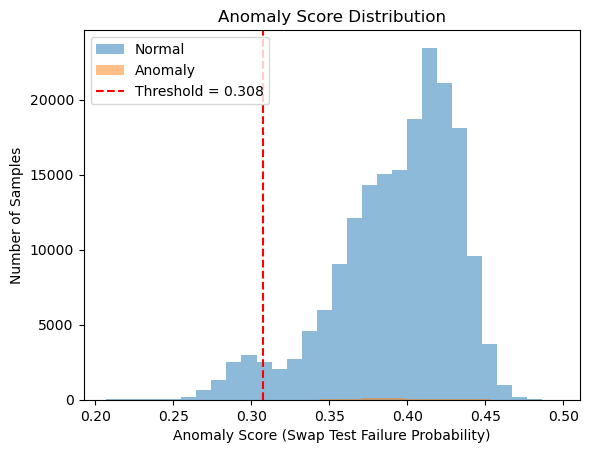

In [82]:
# Get predictions
# v_scores, v_inference_time = compute_anomaly_scores(qnn, scaled_validation_data, trained_params, batch_size=256)

y_pred = (v_scores > threshold).astype(int)
# y_true = np.array(validation_labels).astype(int)
y_true = np.array(validation_labels).astype(int)[:len(v_scores)]

time = inference_time + loading_time

metrics = evaluate_model(
    y_true=y_true,
    y_pred=y_pred,
    scores=v_scores,
    time=time,
    threshold=threshold,  # same threshold used in predict
    model_name="12F Dense + RealAmplitude QAE"
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")

# --- Histogram of scores ---
plt.hist(v_scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(v_scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()
